# 09 - Modelos del ramo y contraste de hipótesis

1. **Comparación con otros métodos (mejora M3):** sobre las mismas 18 features y con el mismo protocolo (CV 5×5,
   seed 0) que Random Forest y XGBoost, se evalúan los clasificadores vistos en el ramo: regresión logística con
   L1 (lasso) y L2 (ridge), con C elegido por CV interna; LDA con encogimiento; KNN; y SVM con kernel RBF. Los
   modelos están en `src/models_classic.py` (`MODELOS_RAMO`).
2. **Contraste de hipótesis (mejora M4):** en vez de decir a ojo "la diferencia está dentro del ruido", se
   contrasta H0: diferencia media = 0 sobre las diferencias pareadas por fold, con el **t-test corregido de
   Nadeau y Bengio** (corrige la dependencia entre folds que comparten datos de entrenamiento) y Wilcoxon como
   complemento. Como se hacen muchas comparaciones, los p-valores se ajustan con **Holm**.

Los resultados por fold se guardan en `results/09_modelos/` (mismo formato que `results/07_ablacion/`).

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import repeated_cv, summarize_cv, choose_threshold, compute_metrics, paired_diff, paired_tests, holm
from src.models_classic import MODELOS_RAMO, make_logistic, select_columns

pd.set_option('display.width', 200)
ACENTO, GRIS, TEXTO = '#2a78d6', '#a3a29d', '#52514e'
OUT, ABL = Path('../results/09_modelos'), Path('../results/07_ablacion')
OUT.mkdir(exist_ok=True)
F = pd.read_csv('../results/features_train.csv')
cols = select_columns(F, 'todas')
X, y = F[cols].to_numpy(), F.label.to_numpy()

## 1. Modelos del ramo (CV 5×5)

También se registra la variante que se probó primero y se descartó: la regresión logística con transformación por
cuantiles (ver la explicación en `src/models_classic.py`).

In [2]:
modelos = dict(MODELOS_RAMO)
modelos['logistica_l2_cuantiles'] = lambda: make_logistic('l2', escalado='cuantiles')
for nombre, make in modelos.items():
    if (OUT / f'{nombre}.csv').exists():
        continue
    folds, oof = repeated_cv(make, X, y, n_splits=5, n_repeats=5)
    folds.to_csv(OUT / f'{nombre}.csv', index=False)
    np.save(OUT / f'{nombre}_oof.npy', oof.astype(np.float32))
    print(nombre, 'listo')

In [3]:
ETIQUETAS = {
    'rf_base': ('Random Forest', ABL), 'xgb_base': ('XGBoost', ABL),
    'knn': ('KNN (k=15)', OUT), 'logistica_l1': ('Logística L1 (lasso)', OUT),
    'logistica_l2': ('Logística L2 (ridge)', OUT), 'lda': ('LDA con encogimiento', OUT), 'svm': ('SVM RBF', OUT),
    'logistica_l2_cuantiles': ('Logística L2 + cuantiles (descartada)', OUT),
}
ref = pd.read_csv(ABL / 'rf_base.csv')
filas = []
for clave, (etiqueta, d) in ETIQUETAS.items():
    folds = pd.read_csv(d / f'{clave}.csv')
    oof = np.load(d / f'{clave}_oof.npy')
    s = summarize_cv(folds)
    thr = choose_threshold(y, oof)
    m = compute_metrics(np.tile(y, len(oof)), oof.ravel(), thr)
    fila = {'modelo': etiqueta, 'pr_auc': s.loc['pr_auc', 'mean'], 'pr_auc_std': s.loc['pr_auc', 'std'],
            'recall@umbral_cv': m['recall'], 'prec@umbral_cv': m['precision']}
    if clave != 'rf_base':
        fila.update({f'vs RF: {k}': v for k, v in paired_tests(paired_diff(folds, ref)).items()
                     if k in ('delta', 'p_t_corregido', 'p_wilcoxon')})
    filas.append(fila)
comp = pd.DataFrame(filas)
mask = comp['vs RF: p_t_corregido'].notna()
comp.loc[mask, 'vs RF: p_holm'] = holm(comp.loc[mask, 'vs RF: p_t_corregido'])
comp.to_csv('../results/09_comparacion_modelos.csv', index=False)
comp.round(3)

,modelo,pr_auc,pr_auc_std,recall@umbral_cv,prec@umbral_cv,vs RF: delta,vs RF: p_t_corregido,vs RF: p_wilcoxon,vs RF: p_holm
0,Random Forest,0.394,0.200,0.324,0.706,NaN,NaN,NaN,NaN
1,XGBoost,0.377,0.186,0.324,0.566,-0.018,0.723,0.381,1.000
2,KNN (k=15),0.378,0.127,0.384,0.696,-0.016,0.803,0.634,1.000
3,Logística L1 (lasso),0.306,0.142,0.259,0.658,-0.089,0.342,0.016,1.000
4,Logística L2 (ridge),0.287,0.159,0.286,0.515,-0.108,0.297,0.005,1.000
5,LDA con encogimiento,0.196,0.111,0.227,0.231,-0.199,0.075,0.000,0.374
6,SVM RBF,0.140,0.128,0.184,0.184,-0.255,0.018,0.000,0.105
7,Logística L2 + cuantiles (descartada),0.104,0.071,0.151,0.130,-0.291,0.010,0.000,0.068


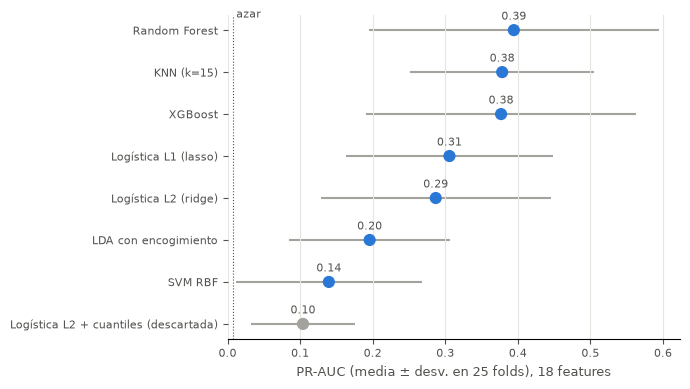

In [4]:
orden = comp.sort_values('pr_auc')
fig, ax = plt.subplots(figsize=(7, 4))
yy = np.arange(len(orden))
colores = [GRIS if 'descartada' in m else ACENTO for m in orden.modelo]
ax.errorbar(orden.pr_auc, yy, xerr=orden.pr_auc_std, fmt='none', ecolor=GRIS, elinewidth=1.5, zorder=1)
ax.scatter(orden.pr_auc, yy, s=60, color=colores, zorder=2)
for yi, v in zip(yy, orden.pr_auc):
    ax.text(v, yi + 0.25, f'{v:.2f}', ha='center', fontsize=8, color=TEXTO)
ax.axvline(0.007, color=TEXTO, lw=0.8, ls=':')
ax.text(0.012, len(orden) - 0.7, 'azar', fontsize=8, color=TEXTO)
ax.set_yticks(yy, orden.modelo, fontsize=9)
ax.set_xlabel('PR-AUC (media ± desv. en 25 folds), 18 features', fontsize=9, color=TEXTO)
ax.set_xlim(left=0)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=TEXTO, labelsize=8)
ax.grid(axis='x', color='#e6e5e0', lw=0.8)
plt.tight_layout()
plt.savefig('../results/09_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

### Selección de features con lasso

La regresión logística L1 entrenada con todo el entrenamiento deja en 0 los coeficientes de las features que no
aportan (con el C elegido por su CV interna). Las features están estandarizadas, así que los coeficientes son
comparables entre sí.

In [5]:
lasso = make_logistic('l1').fit(X, y)
lr = lasso[-1]
coef = pd.Series(lr.coef_[0], index=cols)
print('C elegido por CV interna:', lr.C_[0], '| features con coeficiente distinto de 0:', (coef != 0).sum(), 'de', len(coef))
coef[coef != 0].sort_values(key=abs, ascending=False).round(3)

C:\Users\56975\Desktop\proyecto-cdatos\inf396-exoplanetas\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\56975\Desktop\proyecto-cdatos\inf396-exoplanetas\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
C:\Users\56975\Desktop\proyecto-cdatos\inf396-exoplanetas\.venv\Lib

C elegido por CV interna: 0.1 | features con coeficiente distinto de 0: 15 de 18


fft_peak_ratio    -4.087
fft_high_frac     -1.721
stat_std          -1.016
stat_n_below_3     1.005
bls_n_transits    -0.990
bls_depth          0.838
bls_power_ratio    0.785
bls_period        -0.740
bls_duration      -0.696
fft_low_frac      -0.677
stat_min           0.564
stat_p5            0.434
stat_n_below_5    -0.420
fft_peak_freq      0.400
stat_skew         -0.344
dtype: float64

## 2. Contraste de hipótesis sobre la ablación (notebook 07)

¿Cuáles de los efectos de la ablación clásica son estadísticamente distinguibles de 0? Cada variante se compara
contra la base del mismo modelo, con el t-test corregido y Holm sobre todas las comparaciones de la tabla.

In [6]:
variantes = ['sin_peso', 'sin_detrend', 'sin_recorte', 'ventana_301', 'cadencia_15', 'cadencia_60', 'periodos_15']
filas = []
for m, nombre in [('rf', 'Random Forest'), ('xgb', 'XGBoost')]:
    base = pd.read_csv(ABL / f'{m}_base.csv')
    for v in variantes:
        r = paired_tests(paired_diff(pd.read_csv(ABL / f'{m}_{v}.csv'), base))
        filas.append({'modelo': nombre, 'variante': v, **r})
# CNN (CV 5x1): se agrega sola cuando estén los resultados de run_ablation.py --grupo cnn
if (ABL / 'cnn_base.csv').exists():
    base = pd.read_csv(ABL / 'cnn_base.csv')
    for p in sorted(ABL.glob('cnn_*.csv')):
        if p.stem != 'cnn_base':
            filas.append({'modelo': 'CNN 1D', 'variante': p.stem[4:], **paired_tests(paired_diff(pd.read_csv(p), base))})
    filas.append({'modelo': 'CNN 1D', 'variante': 'base vs Random Forest (5 folds)',
                  **paired_tests(paired_diff(base, pd.read_csv(ABL / 'rf_base.csv')))})
pruebas = pd.DataFrame(filas)
pruebas['p_holm'] = holm(pruebas.p_t_corregido.fillna(1.0))
pruebas['p_wilcoxon_holm'] = holm(pruebas.p_wilcoxon.fillna(1.0))
pruebas['signif. t corregido (Holm)'] = pruebas.p_holm < 0.05
pruebas['signif. Wilcoxon (Holm)'] = pruebas.p_wilcoxon_holm < 0.05
pruebas.to_csv('../results/09_contrastes_ablacion.csv', index=False)
pruebas.drop(columns='n_folds').round(4)

,modelo,variante,delta,t_corregido,p_t_corregido,p_wilcoxon,p_holm,p_wilcoxon_holm,signif. t corregido (Holm),signif. Wilcoxon (Holm)
0,Random Forest,sin_peso,-0.0422,-0.7471,0.4622,0.0802,1.0000,0.3131,False,False
1,Random Forest,sin_detrend,-0.2273,-2.1758,0.0396,0.0000,0.5165,0.0000,False,True
2,Random Forest,sin_recorte,-0.0881,-1.6044,0.1217,0.0000,1.0000,0.0005,False,True
3,Random Forest,ventana_301,-0.1858,-2.2100,0.0369,0.0000,0.5165,0.0000,False,True
4,Random Forest,cadencia_15,-0.0745,-0.9761,0.3387,0.0160,1.0000,0.1278,False,False
5,Random Forest,cadencia_60,0.0397,0.8067,0.4278,0.0755,1.0000,0.3131,False,False
6,Random Forest,periodos_15,0.0169,0.3934,0.6975,0.2521,1.0000,0.3131,False,False
7,XGBoost,sin_peso,0.0288,0.6575,0.5171,0.0903,1.0000,0.3131,False,False
8,XGBoost,sin_detrend,-0.2069,-1.9667,0.0609,0.0000,0.7306,0.0004,False,True
9,XGBoost,sin_recorte,-0.0487,-0.8358,0.4115,0.0393,1.0000,0.2360,False,False


## Conclusiones

**Modelos del ramo (M3).** Con las mismas 18 features, **Random Forest (0,39), KNN (0,38) y XGBoost (0,38) quedan
empatados**: sus diferencias contra el RF son de ~0,02 y no significativas (p > 0,7). Les siguen la regresión
logística con lasso (0,31) o ridge (0,29), LDA (0,20) y SVM RBF (0,14). La relación entre las features y la
etiqueta no es lineal (por ejemplo, "período corto **y** muchos tránsitos"): los modelos que capturan
interacciones o similitud local (árboles, KNN) superan a los lineales. Que KNN, un modelo muy simple, empate con el RF
refuerza que **lo valioso son las features físicas, no la complejidad del clasificador**.

**Lección de preprocesamiento.** La primera versión de estos modelos transformaba las features por cuantiles a una
distribución normal, una transformación no lineal habitual para variables con colas largas, y rendía mucho peor
(logística: 0,10 frente a 0,29). Esa transformación aplasta las colas, y con eventos tan raros **la señal está
justamente en los valores extremos** (SNR y contraste del BLS muy altos). Se reemplazó por la estandarización común.

**Selección con lasso.** Con el C elegido por CV interna (0,1), el lasso conserva 15 de 18 features. Las de mayor
peso son de la FFT (`fft_peak_ratio`, `fft_high_frac`) y del BLS (`bls_n_transits`, `bls_depth`,
`bls_power_ratio`, `bls_period`): coincide con la importancia por permutación del RF (notebook 08) en que se
combinan la FFT y el BLS. Las features están correlacionadas, así que los signos individuales no se deben
interpretar físicamente.

**Contraste de hipótesis (M4).** Hay que distinguir dos pruebas:
- El **t-test corregido de Nadeau y Bengio**, que tiene en cuenta que los folds comparten datos de entrenamiento,
  es conservador. Con Holm sobre las 14 comparaciones de la ablación, **ninguna diferencia resulta significativa**:
  ni siquiera quitar el detrending (Δ = −0,23, p = 0,04 sin ajustar, 0,52 con Holm).
- **Wilcoxon**, que ignora esa dependencia (y por eso es optimista), con Holm sí detecta como significativos los
  efectos del preprocesamiento: quitar el detrending y usar ventana 301 (en ambos modelos) y quitar el recorte de
  picos (solo en el RF).

La conclusión honesta: **la dirección de los efectos grandes es muy consistente** (quitar el detrending solo mejora en
3 de 25 folds), pero con 37 positivos la variabilidad entre folds es tan grande que el experimento no tiene
potencia para confirmarlos formalmente con una prueba conservadora. Los efectos chicos (ponderación de clases,
cadencia de 60 min, períodos de 0,5–15 d, diferencias entre RF, XGBoost y KNN) **no se distinguen del ruido con
ninguna de las dos pruebas** una vez corregidas las comparaciones múltiples, así que no se deben presentar como
mejoras.
